# Input reach: compressed files, URLs, plugin formats and length units

Archived solver output and published datasets often ship compressed. `read` takes them as they are: `cube.msh.gz`, `part.vtu.bz2`, `run.inp.xz`, `skin.stl.zst` and a `case.zip` holding one file. The compression suffix is stripped to infer the format, the file is decompressed into a private temporary directory under the name it had inside, read, and the directory removed. The native registry does the same, so both CLIs (`meshioplusplus convert case.msh.gz case.vtu`), the C API and every binding read them too.

With the optional `fsspec` (the `remote` extra), `read` also takes a URL — `https://`, `s3://`, `gs://` — fetching the file under its own name, so compression and format inference work the same. A separate package can also add a whole format by declaring a `meshioplusplus.formats` entry point. See `doc/formats.md#compressed-files`, `#remote-files` and `doc/extending.md#shipping-a-format-as-a-package`.

In [1]:
import gzip
import bz2
import lzma
import os
import subprocess
import sys
import tempfile
import time
import zipfile

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection

import meshioplusplus as mp


def gl_available():
    # Can PyVista render off-screen here? VTK without a GL/EGL/OSMesa library aborts
    # the process instead of raising, so the probe runs in a child process.
    probe = ("import pyvista as pv; pv.OFF_SCREEN = True; "
             "pl = pv.Plotter(off_screen=True, window_size=(64, 64)); "
             "pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)")
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True, timeout=120).returncode == 0
    except Exception:
        return False


try:
    import pyvista as pv

    if gl_available():
        pv.OFF_SCREEN = True
        pv.set_jupyter_backend('static')
    else:
        pv = None
        print('No GL available: rendering with matplotlib.')
except ImportError:  # pragma: no cover - pyvista is optional here
    pv = None
    print('PyVista unavailable: rendering with matplotlib.')


def draw(ax, mesh, scalars, title):
    """A planar mesh coloured by a cell array: PyVista's render embedded as an
    image when GL is available, else a matplotlib PolyCollection."""
    if pv is not None:
        with tempfile.NamedTemporaryFile(suffix='.vtu', delete=False) as f:
            tmp = f.name
        mp.write(tmp, mesh)
        grid = pv.read(tmp)
        os.unlink(tmp)
        pl = pv.Plotter(off_screen=True, window_size=(800, 600))
        pl.add_mesh(grid, scalars=scalars, show_edges=True, cmap='viridis')
        pl.view_xy()
        ax.imshow(pl.screenshot(return_img=True))
        pl.close()
    else:
        polys = [mesh.points[row, :2] for b in mesh.cells for row in np.asarray(b.data)]
        values = np.concatenate([np.asarray(a).reshape(len(a), -1)[:, 0] for a in mesh.cell_data[scalars]])
        pc = PolyCollection(polys, edgecolor='k', linewidth=0.3, cmap='viridis')
        pc.set_array(values)
        ax.add_collection(pc)
        ax.autoscale()
        ax.set_aspect('equal')
        plt.colorbar(pc, ax=ax, shrink=0.75, label=scalars)
    ax.axis('off')
    ax.set_title(title)

No GL available: rendering with matplotlib.


## One mesh, five compressed copies

A refined plate with a hole, scored for quality, written as ASCII Gmsh — a text format, the kind that compresses well — then compressed with each codec. The zip holds the file under a directory, as an archive downloaded from a dataset portal would; its own name (`case.zip`) has no inner extension, so the member's name (`plate.msh`) says what it is.

In [2]:
mesh, _ = mp.apply_operations(None, [
    {"Op": "Generate", "Shape": "plate_with_hole", "Nt": 16, "Nr": 8},
    {"Op": "Refine"},
    {"Op": "Quality"},
])
workdir = tempfile.mkdtemp()
plain = os.path.join(workdir, 'plate.msh')
mp.write(plain, mesh, file_format='gmsh', binary=False)
raw = open(plain, 'rb').read()


def zip_it(data):
    path = os.path.join(workdir, 'case.zip')
    with zipfile.ZipFile(path, 'w', zipfile.ZIP_DEFLATED) as z:
        z.writestr('dataset/plate.msh', data)
    return open(path, 'rb').read()


copies = {'plate.msh': raw,
          'plate.msh.gz': gzip.compress(raw),
          'plate.msh.bz2': bz2.compress(raw),
          'plate.msh.xz': lzma.compress(raw),
          'case.zip': zip_it(raw)}
try:
    import zstandard
    copies['plate.msh.zst'] = zstandard.ZstdCompressor(level=19).compress(raw)
except ImportError:
    print('zstandard not installed: no .zst copy')

timings = {}
for name, data in copies.items():
    path = os.path.join(workdir, name)
    with open(path, 'wb') as fh:
        fh.write(data)
    t0 = time.perf_counter()
    back = mp.read(path, file_format=None if name == 'case.zip' else 'gmsh')
    timings[name] = time.perf_counter() - t0
    assert np.allclose(back.points, mesh.points) and len(back.cells[0].data) == len(mesh.cells[0].data)
    print(f'{name:15s} {len(data):9,d} bytes  read in {1e3 * timings[name]:6.1f} ms')

plate.msh         521,789 bytes  read in    3.9 ms
plate.msh.gz      109,966 bytes  read in    6.3 ms
plate.msh.bz2     106,318 bytes  read in   19.3 ms
plate.msh.xz       59,256 bytes  read in   10.3 ms
case.zip          112,134 bytes  read in    9.2 ms
plate.msh.zst      69,197 bytes  read in    5.4 ms


The `.msh` suffix is shared by Gmsh, ANSYS Fluent and FreeFem, so `file_format="gmsh"` picks Gmsh, exactly as for the uncompressed file; `case.zip` is read with no format at all and still comes back as Gmsh: of the `.msh` candidates the content sniff picks Gmsh first, as it does for an uncompressed file.

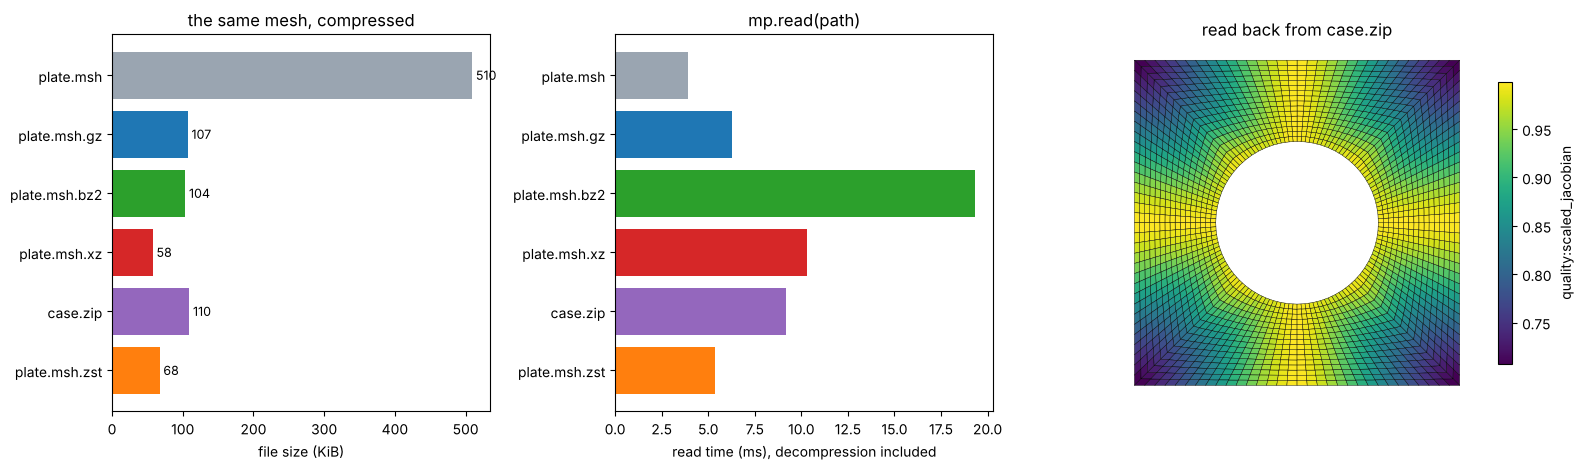

In [3]:
names = list(copies)
sizes = np.array([len(copies[n]) for n in names]) / 1024
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={'width_ratios': [1.1, 1.1, 1.3]})
colours = ['#9aa5b1', '#1f77b4', '#2ca02c', '#d62728', '#9467bd', '#ff7f0e'][: len(names)]
axes[0].barh(names, sizes, color=colours)
axes[0].invert_yaxis()
axes[0].set_xlabel('file size (KiB)')
axes[0].set_title('the same mesh, compressed')
for y, s in enumerate(sizes):
    axes[0].text(s, y, f' {s:.0f}', va='center', fontsize=9)
axes[1].barh(names, [1e3 * timings[n] for n in names], color=colours)
axes[1].invert_yaxis()
axes[1].set_xlabel('read time (ms), decompression included')
axes[1].set_title('mp.read(path)')
back = mp.read(os.path.join(workdir, 'case.zip'))
draw(axes[2], back, 'quality:scaled_jacobian', 'read back from case.zip')
plt.tight_layout()
plt.show()

## What is not stripped, and what is refused

A compound extension a format registers itself stays that format's own: Netgen's `.vol.gz` and libMesh's `.xda.gz` are read by their readers, which decompress them as they always did. A format whose data lives in several files is refused by name, since a decompressed copy in a temporary directory would lose its siblings, and so is a zip with more than one file.

In [4]:
from meshioplusplus import _compressed

for name in ('mesh.vol.gz', 'mesh.xda.gz', 'plate.msh.gz', 'case.zip'):
    print(f'{name:14s} -> compression suffix {_compressed.compression_of(name)!r}')

two = os.path.join(workdir, 'two.zip')
with zipfile.ZipFile(two, 'w') as z:
    z.writestr('a.msh', raw)
    z.writestr('b.msh', raw)
pvtu = os.path.join(workdir, 'pieces.pvtu.gz')
with open(pvtu, 'wb') as fh:
    fh.write(gzip.compress(b'<VTKFile/>'))
for path in (two, pvtu):
    try:
        mp.read(path)
    except mp.ReadError as exc:
        print('ReadError:', exc)

mesh.vol.gz    -> compression suffix ''
mesh.xda.gz    -> compression suffix ''
plate.msh.gz   -> compression suffix '.gz'
case.zip       -> compression suffix '.zip'
ReadError: meshio++: zip: the archive holds 2 files; only a single-file archive is read as a mesh
ReadError: meshio++: '/tmp/tmpi4lf434i/pieces.pvtu.gz' is a compressed pvtu file, whose data spans several files; decompress it first


## Reading from a URL

A local HTTP server stands in for a dataset portal here, serving the directory the copies were written to. `read` fetches `plate.msh.xz` over HTTP, strips `.xz`, and reads the Gmsh file inside; `read_metadata` summarises a URL the same way. An object store works alike (`s3://bucket/...` with `s3fs` installed), and a whole time series can be a URL pattern (`sequence_entries("s3://bucket/run/step_*.vtu")`).

127.0.0.1 - - [01/Nov/2026 22:18:10] "HEAD /plate.msh.xz HTTP/1.1" 200 -
127.0.0.1 - - [01/Nov/2026 22:18:10] "GET /plate.msh.xz HTTP/1.1" 200 -
127.0.0.1 - - [01/Nov/2026 22:18:10] "HEAD /case.zip HTTP/1.1" 200 -
127.0.0.1 - - [01/Nov/2026 22:18:10] "GET /case.zip HTTP/1.1" 200 -


http://127.0.0.1:37027/plate.msh.xz -> 2176 points; case.zip summary: gmsh 2048 cells


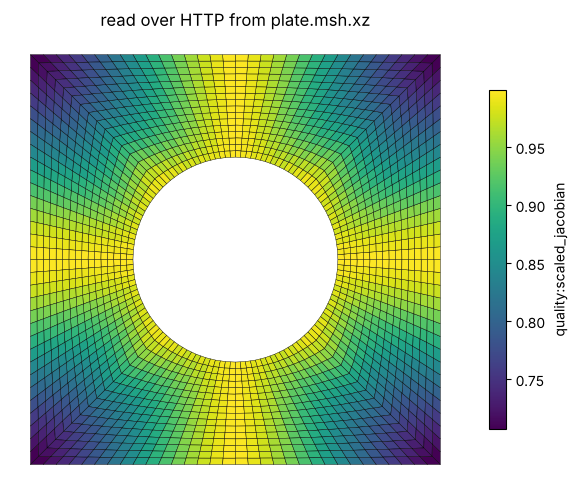

In [5]:
import functools
import http.server
import threading

try:
    import fsspec  # noqa: F401
    have_fsspec = True
except ImportError:
    have_fsspec = False
    print('fsspec not installed: pip install meshioplusplus[remote]')

if have_fsspec:
    handler = functools.partial(http.server.SimpleHTTPRequestHandler, directory=workdir)
    handler.log_message = lambda *a, **k: None
    server = http.server.ThreadingHTTPServer(('127.0.0.1', 0), handler)
    threading.Thread(target=server.serve_forever, daemon=True).start()
    base = f'http://127.0.0.1:{server.server_address[1]}'
    url = f'{base}/plate.msh.xz'
    remote = mp.read(url, file_format='gmsh')
    meta = mp.read_metadata(f'{base}/case.zip')
    print(url, '->', len(remote.points), 'points;', 'case.zip summary:', meta['format'], meta['num_cells'], 'cells')
    server.shutdown()

    fig, ax = plt.subplots(figsize=(6, 5))
    draw(ax, remote, 'quality:scaled_jacobian', 'read over HTTP from plate.msh.xz')
    plt.tight_layout()
    plt.show()

## A format from an installed package

A package adds a format by declaring a `meshioplusplus.formats` entry point; installing it is all it takes. Below, a throwaway distribution is written to a temporary directory and put on `sys.path`, which is what `pip install` would do: its entry point registers a tiny text format, `.tri` (a `v x y z` line per point and a `t a b c` line per triangle), and `read` and `write` take it with no other step.

v 0.0 0.0 0.0
v 0.125 0.0 0.0
v 0.25 0.0 0.0
v 0.375 0.0 0.0
v 0.5 0.0 0.0
v 0.625 0.0 0.0
v 0.75 0. ...
'tri' readable now: True


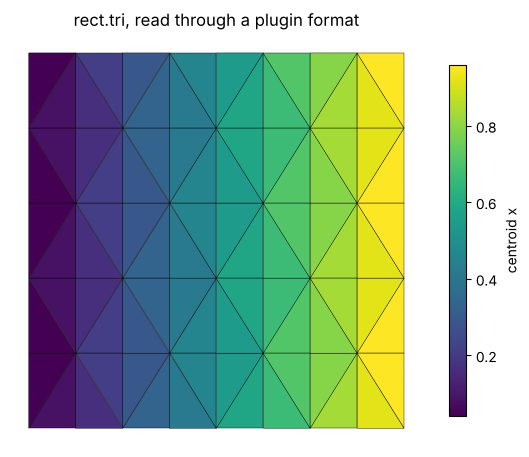

In [6]:
import importlib

PLUGIN_SOURCE = '''
import numpy as np
import meshioplusplus


def read(path):
    rows = [line.split() for line in open(path) if line.strip()]
    pts = np.array([[float(v) for v in r[1:]] for r in rows if r[0] == "v"])
    tris = np.array([[int(v) for v in r[1:]] for r in rows if r[0] == "t"])
    return meshioplusplus.Mesh(pts, [("triangle", tris)])


def write(path, mesh, **kwargs):
    with open(path, "w") as out:
        for p in mesh.points:
            out.write("v %r %r %r\\n" % tuple(float(x) for x in p))
        for c in mesh.cells_dict["triangle"]:
            out.write("t %d %d %d\\n" % tuple(c))


def register():
    meshioplusplus.register_format("tri", [".tri"], read, {"tri": write})
'''

plugin_dir = tempfile.mkdtemp()
with open(os.path.join(plugin_dir, 'tri_format.py'), 'w') as fh:
    fh.write(PLUGIN_SOURCE)
info = os.path.join(plugin_dir, 'tri_format-1.0.dist-info')
os.makedirs(info)
with open(os.path.join(info, 'METADATA'), 'w') as fh:
    fh.write('Metadata-Version: 2.1\nName: tri-format\nVersion: 1.0\n')
with open(os.path.join(info, 'entry_points.txt'), 'w') as fh:
    fh.write('[meshioplusplus.formats]\ntri = tri_format:register\n')
sys.path.insert(0, plugin_dir)
importlib.invalidate_caches()

# The registry discovers entry points on its first use. In a fresh process
# that is the first read; this notebook has used it already, so ask for the
# discovery again, as a new interpreter would do on its own.
from meshioplusplus import _plugins
_plugins.load_format_plugins(force=True)

disk, _ = mp.apply_operations(None, [
    {"Op": "Generate", "Shape": "rectangle", "Dims": [8, 5], "CellType": "triangle"},
])
path = os.path.join(workdir, 'rect.tri')
mp.write(path, mp.Mesh(disk.points, disk.cells))
print(open(path).read()[:100], '...')
back = mp.read(path)
back.cell_data = {'centroid x': [back.points[back.cells[0].data].mean(axis=1)[:, 0]]}
print("'tri' readable now:", 'tri' in mp.formats()['readable'])
fig, ax = plt.subplots(figsize=(5.5, 5))
draw(ax, back, 'centroid x', 'rect.tri, read through a plugin format')
plt.tight_layout()
plt.show()

## Length units travel with the mesh

A file that states its length unit hands it on: `field_data["meshio:length_unit"]` holds the metres per mesh unit. UNV's dataset 164, Radioss's `/BEGIN` units and USD's `metersPerUnit` fill it and honour it, and `transform(scale_units=...)` updates it. Below, a plate in millimetres is written as UNV (dataset 164, code 5), read back, converted to metres, and both are drawn on axes labelled with the unit each mesh states.

['    -1', '   164', '         5                             2', '   1.0000000000000000E+03   1.0000000000000000E+03   1.0000000000000000E+00']


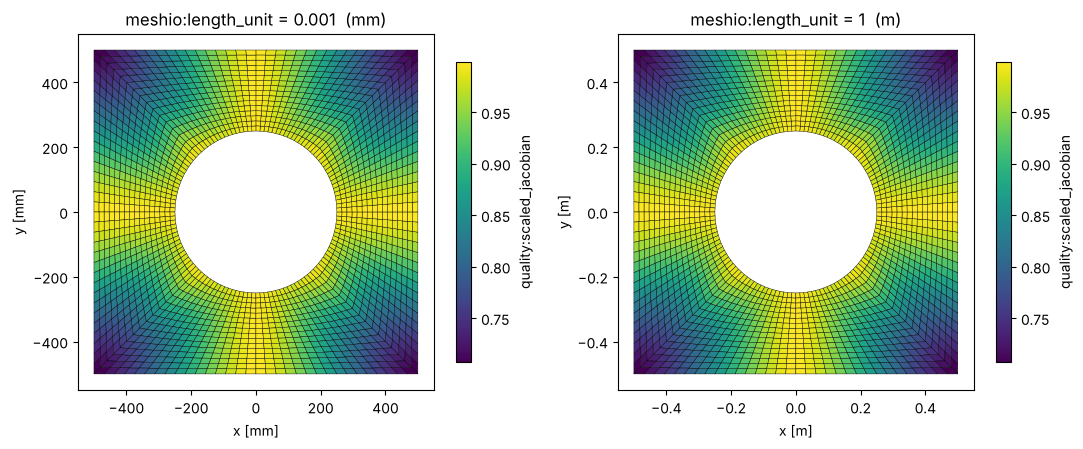

In [7]:
from meshioplusplus import _units

plate_mm = mp.Mesh(mesh.points * 1000.0, mesh.cells, cell_data=mesh.cell_data)
_units.set_length_unit(plate_mm, 0.001)
unv = os.path.join(workdir, 'plate_mm.unv')
mp.write(unv, plate_mm)
print(open(unv).read().split('\n')[:4])

back = mp.read(unv)
metres = mp.transform(back, scale_units=0.001)
names = {1.0: 'm', 0.001: 'mm'}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, m in ((axes[0], back), (axes[1], metres)):
    unit = _units.length_unit(m)
    m.cell_data = {'quality:scaled_jacobian': back.cell_data.get('quality:scaled_jacobian', mesh.cell_data['quality:scaled_jacobian'])}
    draw(ax, m, 'quality:scaled_jacobian', f'meshio:length_unit = {unit:g}  ({names.get(unit, "?")})')
    ax.axis('on')
    ax.set_xlabel(f'x [{names.get(unit, "?")}]')
    ax.set_ylabel(f'y [{names.get(unit, "?")}]')
plt.tight_layout()
plt.show()